In [1]:
import dpluspy 
import numpy as np
import pickle
import gzip

In [18]:
# Bherer map
u_bar = 1.122153e-08
bins = np.concatenate([[0], np.logspace(-6, -1, 21), [0.5]])
pop_fname = "../../data/vcf_files/populations8"

naive_raw_sums = dict()
raw_sums = dict()

for chrom in range(1, 23):
    vcf_fname = f"../../data/vcf_files/merged/merged.variants.chr{chrom}.vcf.gz"
    rec_fname = f"../../data/recombination_maps/Bherer/sexavg_chr{chrom}.txt.gz"
    mut_fname = f"../../data/mutation_maps/roulette/map_chr{chrom}.npy.gz"
    bed_fname = f"../../data/bed_files/accessible_1e-4M_ccds_flank/mask_chr{chrom}.bed.gz"
    # window_fname = f"../../data/windows/1e-4M_buffer/windows_chr{chrom}.txt"
    ws = 5000000
    with gzip.open(mut_fname, "rb") as fin:
        L = len(np.load(fin))
    intervals = [[i * ws, (i + 1) * ws, (i + 1) * ws] for i in range(int(L//ws) + 1)]
    
    chrom_sums = dpluspy.parsing.parse_stats(
        vcf_fname,
        bed_file=bed_fname,
        rec_map_file=rec_fname,
        mut_map_file=mut_fname,
        intervals=intervals,
        pos_col="pos",
        map_col="cM",
        r_bins=bins,
        chrom=chrom,
        u_bar=u_bar,
        label_file=pop_fname
    )
    raw_sums.update(chrom_sums)

# Perform bootstrap sampling
pop_ids = raw_sums[next(iter(raw_sums))]["pop_ids"]
stats, varcovs = dpluspy.bootstrapping.bootstrap_stats(raw_sums)
reps = dpluspy.bootstrapping.get_bootstrap_reps(raw_sums)
data = {
    "means": stats, 
    "varcovs": varcovs,
    "bootreps": reps,
    "bins": bins,
    "pop_ids": pop_ids
}
# with open("bherer_weighted_stats.pkl", "wb") as fout:
#     pickle.dump(data, fout)

[2026-09-09 20:49:10] Computed stats within chrom 1 interval 0 0-5000000
[2026-09-09 20:49:11] Computed stats within chrom 1 interval 1 5000000-10000000
[2026-09-09 20:49:11] Computed stats within chrom 1 interval 2 10000000-15000000
[2026-09-09 20:49:12] Computed stats within chrom 1 interval 3 15000000-20000000
[2026-09-09 20:49:12] Computed stats within chrom 1 interval 4 20000000-25000000
[2026-09-09 20:49:12] Computed stats within chrom 1 interval 5 25000000-30000000
[2026-09-09 20:49:13] Computed stats within chrom 1 interval 6 30000000-35000000
[2026-09-09 20:49:14] Computed stats within chrom 1 interval 7 35000000-40000000
[2026-09-09 20:49:14] Computed stats within chrom 1 interval 8 40000000-45000000
[2026-09-09 20:49:14] Computed stats within chrom 1 interval 9 45000000-50000000
[2026-09-09 20:49:14] Computed stats within chrom 1 interval 10 50000000-55000000
[2026-09-09 20:49:15] Computed stats within chrom 1 interval 11 55000000-60000000
[2026-09-09 20:49:16] Computed stat

In [20]:
to_pops = ["Altai", "Vindija", "Chagyrskaya", "Denisova", "Stuttgart", "Loschbour", "UstIshim", "Yoruba1"]
bins, means, varcovs = dpluspy.bootstrapping.subset_stats(data, to_pops=to_pops, min_r=1e-6, max_r=1e-2)

In [21]:
model = dpluspy.inference.compute_bin_stats("../../models/main_models/bherer_full.yaml", sampled_demes=to_pops,
                                            u=1.3e-8, bins=bins)

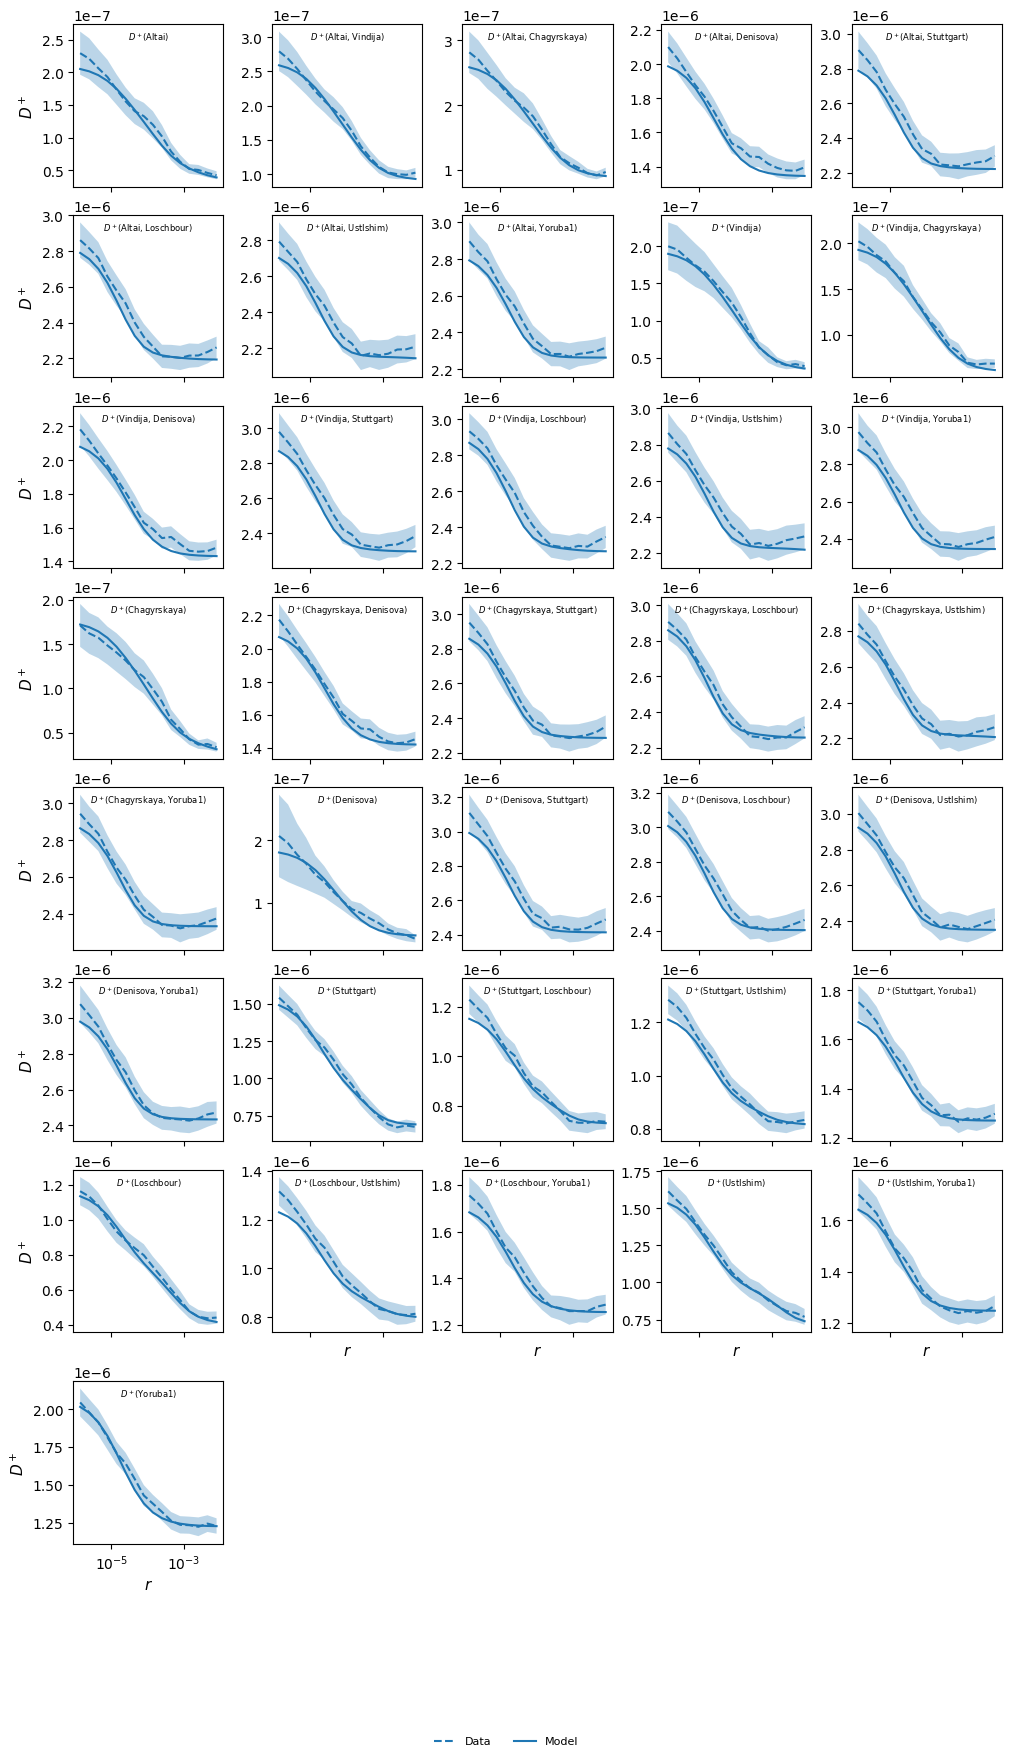

In [22]:
dpluspy.plotting.plot_D_plus_curves(
    models=model,
    means=means,
    varcovs=varcovs,
    pop_ids=to_pops,
    bins=bins)

In [33]:
np.sum([raw_sums[x]["sums"] for x in raw_sums], axis=0)[1:18]

array([[4.76005234e+04, 5.79868100e+04, 5.84404348e+04, 4.36077632e+05,
        6.03527190e+05, 5.94099572e+05, 5.79679937e+05, 6.01432578e+05,
        6.11080710e+05, 6.00657525e+05, 4.14641354e+04, 4.20039767e+04,
        4.53043927e+05, 6.18693828e+05, 6.09123289e+05, 5.94657686e+05,
        6.17334552e+05, 6.24153916e+05, 6.16332758e+05, 3.55319110e+04,
        4.51497437e+05, 6.12730812e+05, 6.03389548e+05, 5.89425532e+05,
        6.11111026e+05, 6.17760832e+05, 6.10421584e+05, 4.28970035e+04,
        6.45627558e+05, 6.41544616e+05, 6.23854148e+05, 6.38618080e+05,
        6.40868938e+05, 6.32580705e+05, 3.20038753e+05, 2.55017486e+05,
        2.66840916e+05, 3.63629349e+05, 3.60193784e+05, 3.63251911e+05,
        2.41743263e+05, 2.73056875e+05, 3.64360060e+05, 3.70698938e+05,
        3.64714170e+05, 3.35016548e+05, 3.53107302e+05, 3.48887642e+05,
        3.54890749e+05, 4.24300282e+05, 3.34275603e+05, 3.34406526e+05,
        4.27700241e+05, 3.37313758e+05, 4.28046896e+05],
       

In [3]:
# Zhou map 

naive_raw_sums = dict()
raw_sums = dict()

for chrom in range(1, 23):
    vcf_fname = f"../../data/vcf_files/merged/merged.variants.chr{chrom}.vcf.gz"
    rec_fname = f"../../data/recombination_maps/Zhou/JHS/JHS.chr{chrom}.1000.plinkmap.txt.gz"
    mut_fname = f"../../data/mutation_maps/roulette/map_chr{chrom}.npy"
    bed_fname = f"../../data/bed_files/1e-4M_buffer/mask_chr{chrom}.bed.gz"
    window_fname = f"../../data/windows/1e-4M_buffer/windows_chr{chrom}.txt"
    
    chrom_sums = dpluspy.parsing.parse_stats(
        vcf_fname,
        bed_file=bed_fname,
        rec_map_file=rec_fname,
        mut_map_file=mut_fname,
        interval_file=window_fname,
        pos_col="Position(bp)",
        map_col="Map(cM)",
        r_bins=bins,
        chrom=chrom,
        u_bar=u_bar,
        label_file=pop_fname
    )
    raw_sums.update(chrom_sums)
    
    naive_chrom_sums = dpluspy.parsing.parse_stats(
        vcf_fname,
        bed_file=bed_fname,
        rec_map_file=rec_fname,
        interval_file=window_fname,
        pos_col="Position(bp)",
        map_col="Map(cM)",
        r_bins=bins,
        chrom=chrom,
        label_file=pop_fname,
        get_denoms=False
    )
    for label in naive_chrom_sums:
        naive_chrom_sums[label]["denoms"] = chrom_sums[label]["denoms"]
    naive_raw_sums.update(naive_chrom_sums)


# Save raw numerators/denominators 
with open("zhou_weighted_raw_sums.pkl", "wb") as fout:
    pickle.dump(raw_sums, fout)

with open("zhou_naive_raw_sums.pkl", "wb") as fout:
    pickle.dump(naive_raw_sums, fout)
    

# Perform bootstrap sampling
pop_ids = raw_sums[next(iter(raw_sums))]["pop_ids"]
stats, varcovs = dpluspy.bootstrapping.bootstrap_stats(raw_sums)
reps = dpluspy.bootstrapping.get_bootstrap_reps(raw_sums)
data = {
    "means": stats, 
    "varcovs": varcovs,
    "bootreps": reps,
    "bins": bins,
    "pop_ids": pop_ids
}
with open("zhou_weighted_stats.pkl", "wb") as fout:
    pickle.dump(data, fout)

naive_stats, naive_varcovs = dpluspy.bootstrapping.bootstrap_stats(naive_raw_sums)
naive_reps = dpluspy.bootstrapping.get_bootstrap_reps(naive_raw_sums)
data = {
    "means": naive_stats, 
    "varcovs": naive_varcovs,
    "bootreps": naive_reps,
    "bins": bins,
    "pop_ids": pop_ids
}
with open("zhou_naive_stats.pkl", "wb") as fout:
    pickle.dump(data, fout)

[2026-02-24 13:19:25] Computed stats within chrom 1 interval 0 1-7047600
[2026-02-24 13:19:27] Computed stats between chrom 1 intervals 0 1-118298144-118298144
[2026-02-24 13:19:28] Computed stats within chrom 1 interval 1 7047600-14672369
[2026-02-24 13:19:29] Computed stats between chrom 1 intervals 1 7047600-118298144-118298144
[2026-02-24 13:19:30] Computed stats within chrom 1 interval 2 14672369-21688374
[2026-02-24 13:19:31] Computed stats between chrom 1 intervals 2 14672369-118298144-118298144
[2026-02-24 13:19:32] Computed stats within chrom 1 interval 3 21688374-30997738
[2026-02-24 13:19:33] Computed stats between chrom 1 intervals 3 21688374-118298144-118298144
[2026-02-24 13:19:34] Computed stats within chrom 1 interval 4 30997738-38897784
[2026-02-24 13:19:35] Computed stats between chrom 1 intervals 4 30997738-118298144-118298144
[2026-02-24 13:19:36] Computed stats within chrom 1 interval 5 38897784-48587016
[2026-02-24 13:19:37] Computed stats between chrom 1 interval